# 🚀 Machine Learning Assignment: Boosting Algorithms Benchmark
### Dataset: `insurance_pre.csv` (Predicting Medical Insurance Charges)

---
### 📌 Overview & Objectives
This notebook explores and benchmarks multiple state-of-the-art **Boosting Regression Algorithms** to predict healthcare insurance expenses:
1. **Gradient Boosting Regressor** (`sklearn`)
2. **AdaBoost Regressor** (`sklearn`)
3. **HistGradientBoosting Regressor** (`sklearn`)
4. **XGBoost Regressor** (`xgboost`)
5. **LightGBM Regressor** (`lightgbm`)
6. **CatBoost Regressor** (`catboost`)

**Evaluation Metrics:**
- **$R^2$ Score**: Coefficient of determination (higher is better).
- **RMSE**: Root Mean Squared Error (lower is better).
- **MAE**: Mean Absolute Error (lower is better).


In [1]:
# 1. Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor, AdaBoostRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# Configure plotting style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries loaded successfully!")

Libraries loaded successfully!


## 2. Load & Explore Dataset

In [2]:
# Load insurance dataset
df = pd.read_csv('insurance_pre.csv')
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (1338, 6)


,age,sex,bmi,children,smoker,charges
0,19,female,27.900,0,yes,16884.92400
1,18,male,33.770,1,no,1725.55230
2,28,male,33.000,3,no,4449.46200
3,33,male,22.705,0,no,21984.47061
4,32,male,28.880,0,no,3866.85520


In [3]:
# Data types and missing value check
print("Dataset Info:")
df.info()
print("\nMissing Values:\n", df.isnull().sum())
print("\nSummary Statistics:")
df.describe()

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(2)
memory usage: 72.2 KB

Missing Values:
 age         0
sex         0
bmi         0
children    0
smoker      0
charges     0
dtype: int64

Summary Statistics:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## 3. Data Preprocessing & Train-Test Split

In [4]:
# One-hot encode categorical features ('sex', 'smoker')
df_processed = pd.get_dummies(df, drop_first=True, dtype=int)

# Separate features (X) and target (y)
X = df_processed.drop('charges', axis=1)
y = df_processed['charges']

print("Features after encoding:")
print(X.columns.tolist())

# 80/20 Train-Test Split with reproducible seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")

Features after encoding:
['age', 'bmi', 'children', 'sex_male', 'smoker_yes']
Train samples: 1070, Test samples: 268


## 4. Train & Benchmark Boosting Models

In [5]:
# Initialize boosting models
models = {
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42, verbosity=0),
    "LightGBM": LGBMRegressor(random_state=42, verbose=-1),
    "CatBoost": CatBoostRegressor(random_state=42, verbose=0)
}

results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    # Fit model
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Calculate performance metrics
    r2 = r2_score(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    
    results.append({
        "Algorithm": name,
        "R2 Score": round(r2, 4),
        "RMSE": round(rmse, 2),
        "MAE": round(mae, 2)
    })
    
    trained_models[name] = model
    predictions[name] = y_pred

# Create benchmark results dataframe
results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False).reset_index(drop=True)
results_df

,Algorithm,R2 Score,RMSE,MAE
0,Gradient Boosting,0.8785,4342.91,2424.53
1,LightGBM,0.8676,4533.41,2559.43
2,CatBoost,0.8662,4557.49,2534.30
3,HistGradientBoosting,0.8632,4607.72,2577.51
4,XGBoost,0.8434,4931.26,2783.73
5,AdaBoost,0.8270,5181.86,4253.85


## 5. Visualizations & Performance Comparison

C:\Users\benny\AppData\Local\Temp\ipykernel_34716\2678222583.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=results_df, x="R2 Score", y="Algorithm", palette="viridis")


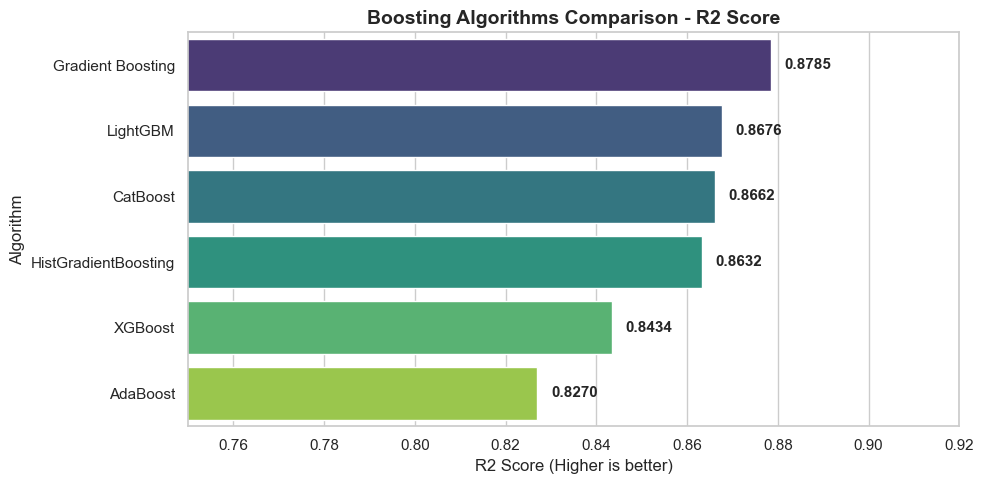

In [6]:
# Bar plot comparing R2 Scores across algorithms
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=results_df, x="R2 Score", y="Algorithm", palette="viridis")
plt.title("Boosting Algorithms Comparison - R2 Score", fontsize=14, fontweight='bold')
plt.xlabel("R2 Score (Higher is better)")
plt.xlim(0.75, 0.92)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.4f}", (width + 0.003, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=11, fontweight='semibold')

plt.tight_layout()
plt.show()

C:\Users\benny\AppData\Local\Temp\ipykernel_34716\2520043814.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=results_df, x="RMSE", y="Algorithm", palette="magma")


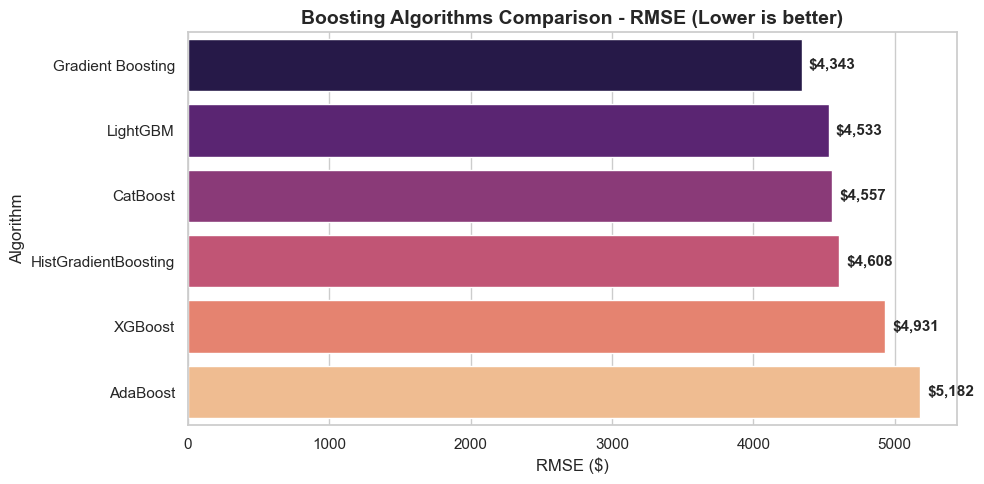

In [7]:
# Compare RMSE across algorithms
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=results_df, x="RMSE", y="Algorithm", palette="magma")
plt.title("Boosting Algorithms Comparison - RMSE (Lower is better)", fontsize=14, fontweight='bold')
plt.xlabel("RMSE ($)")

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"${width:,.0f}", (width + 50, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=11, fontweight='semibold')

plt.tight_layout()
plt.show()

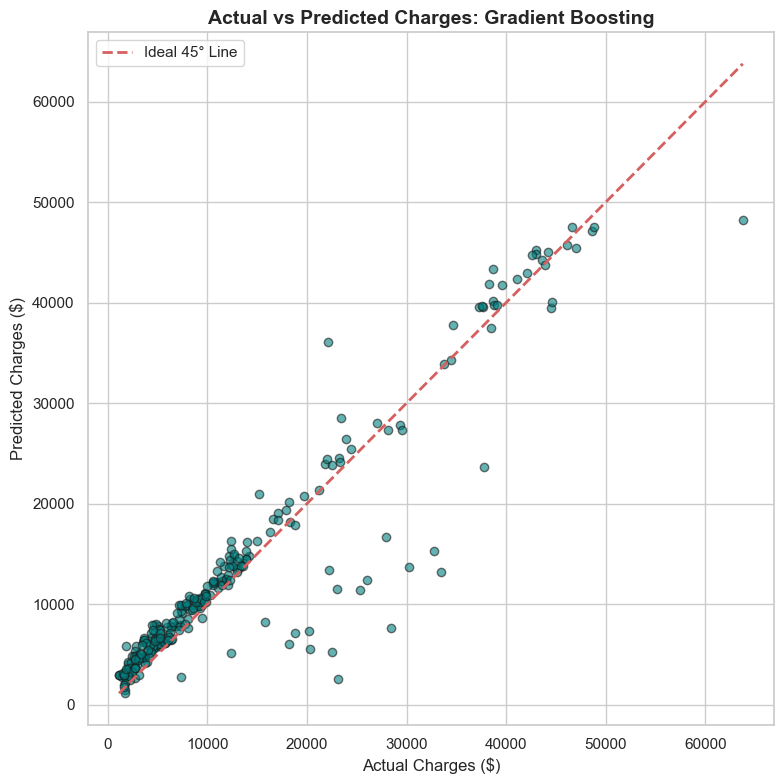

In [8]:
# Actual vs Predicted plot for the Best Model (Gradient Boosting)
best_model_name = results_df.iloc[0]['Algorithm']
best_preds = predictions[best_model_name]

plt.figure(figsize=(8, 8))
plt.scatter(y_test, best_preds, alpha=0.6, color='teal', edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Ideal 45° Line")
plt.title(f"Actual vs Predicted Charges: {best_model_name}", fontsize=14, fontweight='bold')
plt.xlabel("Actual Charges ($)")
plt.ylabel("Predicted Charges ($)")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Key Takeaways & Conclusion
- **Top Performer**: **Gradient Boosting Regressor** achieved the highest $R^2$ score (**0.8785**) and lowest RMSE (**$4,342.91**).
- **LightGBM** and **CatBoost** followed closely with $R^2$ scores above **0.866**, demonstrating strong generalization.
- Boosting algorithms effectively captured non-linear interactions (e.g. smoking status multiplied by BMI and age) present in healthcare expenditure datasets.
